# Adim 6.3: Makine Ogrenmesi - Lineer Regresyon

Bu notebook'ta, ozellik muhendisligi tamamlanmis NYC Taxi verilerini kullanarak **Linear Regression** modelini egitecegiz.

### Bu Adimda Yapilacaklar:
1. **Veri Yukleme:** feature(Gold) katmanindan (Step 5) verilerin okunmasi.
2. **Ozellik Hazirligi:** Verilerin vektor formuna getirilmesi ve Train/Test ayrimi.
3. **MLflow Entegrasyonu:** Tum parametre ve metriklerin loglanmasi.
4. **Model Degerlendirme:** RMSE, MAE, R² ve Residual analizi.
5. **Ozellik Onemi:** Feature Importance (katsayi) analizi.

In [7]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
import mlflow
import mlflow.spark
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Spark Oturumunu Baslat (Delta destegi ile)
spark = SparkSession.builder \
    .appName("NYC-Taxi-ModelTraining-LR") \
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.1.0") \
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog") \
    .getOrCreate()

# MLflow Ayarlari
mlflow.set_tracking_uri("http://mlflow-server:5001")
mlflow.set_experiment("Taxi_Fare_Prediction")

print("Spark ve MLflow Hazir.")

Spark ve MLflow Hazir.


## 1. Veri Okuma
Adim 5'te kaydettigimiz Gold tablosunu yukluyoruz.

In [8]:
gold_path = "/home/jovyan/work/data/delta/features"
df = spark.read.format("delta").load(gold_path)

print(f"Egitim icin yuklenen toplam kayit sayisi: {df.count()}")
df.printSchema()

Egitim icin yuklenen toplam kayit sayisi: 1798960
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- trip_duration_min: double (nullable = true)
 |-- average_speed: double 

## 2. Ozelliklerin Vektorlestirilmesi
Spark ML algoritmalari, girdi ozelliklerini tek bir `features` sutununda vektor olarak bekler.

In [9]:
# Modelde kullanilacak ozellikler
feature_cols = [
    "trip_distance", 
    "trip_duration_min", 
    "average_speed", 
    "pickup_hour", 
    "day_of_week", 
    "is_airport_trip", 
    "is_rush_hour"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
final_df = assembler.transform(df).select("features", "total_amount")

# Veriyi %80 Egitim, %20 Doğrulama olarak ayiriyoruz
train_df, validation_df = final_df.randomSplit([0.8, 0.2], seed=42)

print(f"Egitim seti: {train_df.count()} kayit")
print(f"Doğrulama seti: {validation_df.count()} kayit")

Egitim seti: 1439385 kayit
Doğrulama seti: 359575 kayit


## 3. Lineer Regresyon Modeli Egitimi ve MLflow Kaydi

In [10]:
with mlflow.start_run(run_name="Linear_Regression_Final"):
    # 1. Model Parametreleri
    max_iter = 100
    reg_param = 0.01
    elastic_net = 0.0  # 0 = L2 (Ridge), 1 = L1 (Lasso)
    
    lr = LinearRegression(
        featuresCol="features", 
        labelCol="total_amount", 
        maxIter=max_iter, 
        regParam=reg_param,
        elasticNetParam=elastic_net
    )
    
    # 2. Modeli Egit
    print("Lineer Regresyon Modeli egitiliyor, lutfen bekleyin...")
    model = lr.fit(train_df)
    
    # 3. Tahmin Yap
    predictions = model.transform(validation_df)
    
    # 4. Metrikleri Hesapla
    evaluator_rmse = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="rmse")
    evaluator_mae = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="mae")
    evaluator_r2 = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="r2")
    
    rmse = evaluator_rmse.evaluate(predictions)
    mae = evaluator_mae.evaluate(predictions)
    r2 = evaluator_r2.evaluate(predictions)
    
    # 5. MLflow'a Logla
    mlflow.log_param("model_type", "LinearRegression")
    mlflow.log_param("maxIter", max_iter)
    mlflow.log_param("regParam", reg_param)
    mlflow.log_param("elasticNetParam", elastic_net)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("r2", r2)
    
    mlflow.spark.log_model(model, "lr_model")
    
    print(f"Model Basariyla Egitildi.")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE: {mae:.2f}")
    print(f"R2 Score: {r2:.2f}")
    print(f"\nModel Intercept: {model.intercept:.4f}")

Lineer Regresyon Modeli egitiliyor, lutfen bekleyin...
Model Basariyla Egitildi.
RMSE: 7.26
MAE: 3.39
R2 Score: 0.89

Model Intercept: 8.4718
🏃 View run Linear_Regression_Final at: http://mlflow-server:5001/#/experiments/1/runs/29c098d0b2e84cecab8593c864f07035
🧪 View experiment at: http://mlflow-server:5001/#/experiments/1


## 4. Ozellik Onemi (Feature Importance - Katsayilar)

Lineer regresyonda **katsayilar (coefficients)** ozellik onemini gosterir.
Buyuk mutlak deger = yuksek etki. Pozitif katsayi fiyati arttirir, negatif katsayi dusurur.

Ozellik Katsayilari:
          Feature  Coefficient
  is_airport_trip     6.925488
    trip_distance     3.612907
     is_rush_hour     1.128866
trip_duration_min     0.287038
      pickup_hour     0.062290
    average_speed     0.043364
      day_of_week     0.040479

Intercept (sabit): 8.4718


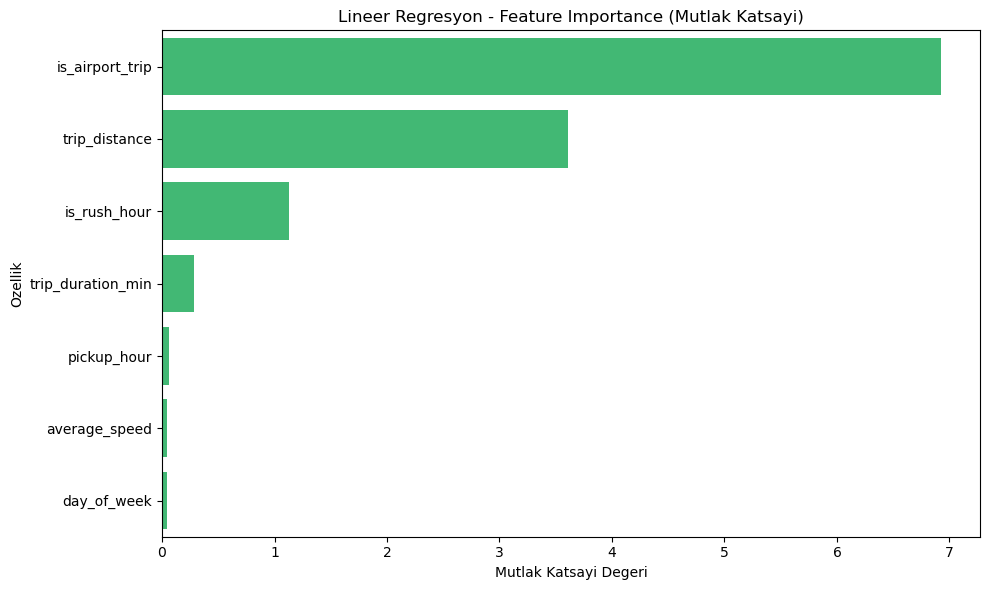

In [11]:
# Lineer regresyonda ozellik onemi = katsayilarin mutlak degeri
coefficients = model.coefficients.toArray()

feat_imp_df = pd.DataFrame({
    'Feature': feature_cols, 
    'Coefficient': coefficients,
    'Abs_Importance': np.abs(coefficients)
})
feat_imp_df = feat_imp_df.sort_values(by='Abs_Importance', ascending=False)

# Katsayi tablosu
print("Ozellik Katsayilari:")
print(feat_imp_df[['Feature', 'Coefficient']].to_string(index=False))
print(f"\nIntercept (sabit): {model.intercept:.4f}")

# Gorsel: Mutlak onem
plt.figure(figsize=(10, 6))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in feat_imp_df['Coefficient']]
sns.barplot(x='Abs_Importance', y='Feature', data=feat_imp_df, hue='Feature', palette=colors, legend=False)
plt.title('Lineer Regresyon - Feature Importance (Mutlak Katsayi)')
plt.xlabel('Mutlak Katsayi Degeri')
plt.ylabel('Ozellik')
plt.tight_layout()
plt.show()

## 5. Gercek vs Tahmin & Residual Analizi

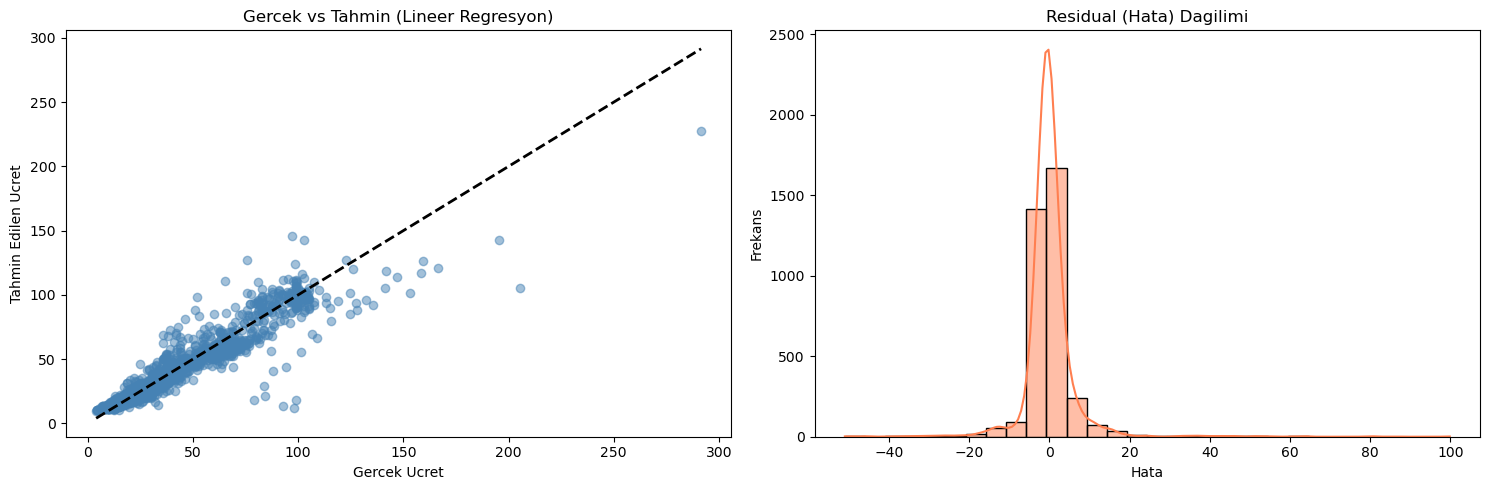

In [12]:
# Analiz icin bir orneklem alalim
preds_pd = predictions.select("total_amount", "prediction").sample(0.01).toPandas()
preds_pd['residual'] = preds_pd['total_amount'] - preds_pd['prediction']

plt.figure(figsize=(15, 5))

# 1. Gercek vs Tahmin Scatter Plot
plt.subplot(1, 2, 1)
plt.scatter(preds_pd['total_amount'], preds_pd['prediction'], alpha=0.5, color='steelblue')
plt.plot([preds_pd['total_amount'].min(), preds_pd['total_amount'].max()], 
         [preds_pd['total_amount'].min(), preds_pd['total_amount'].max()], 'k--', lw=2)
plt.xlabel('Gercek Ucret')
plt.ylabel('Tahmin Edilen Ucret')
plt.title('Gercek vs Tahmin (Lineer Regresyon)')

# 2. Residual Dagilimi
plt.subplot(1, 2, 2)
sns.histplot(preds_pd['residual'], bins=30, kde=True, color='coral')
plt.title('Residual (Hata) Dagilimi')
plt.xlabel('Hata')
plt.ylabel('Frekans')

plt.tight_layout()
plt.show()